# So sánh AdaBoost và Gradient Boosting trong dự đoán giá thuê
### Thiết kế thực nghiệm, đánh giá sai số và khuyến nghị sử dụng

**Bài toán:** dự đoán **giá chào thuê hằng tháng** (`price_vnd`, đơn vị VND/tháng) của tin đăng NhaTot từ diện tích, quận/huyện và tình trạng nội thất. Giá chào thuê không đồng nghĩa với giá giao dịch thực tế.

**Mục đích so sánh:** xác định mô hình nào phù hợp hơn với **bộ dữ liệu và ba biến đầu vào hiện có**, xét đồng thời sai số dự đoán, khả năng hạn chế sai số lớn, độ ổn định và chi phí huấn luyện. Không đặt trước kết luận rằng thuật toán nào luôn tốt hơn.

## 1. Câu hỏi nghiên cứu và tiêu chí ra quyết định

1. Hai mô hình giảm **MAE** bao nhiêu VND và bao nhiêu phần trăm so với dự đoán trung vị?
2. Khi được tinh chỉnh trên cùng các fold và cùng số cấu hình thử, mô hình nào có MAE kiểm định chéo thấp hơn?
3. Kết quả trên tập kiểm tra giữ riêng có nhất quán với lựa chọn đó không? Chênh lệch MAE giữa hai mô hình có ổn định trong bootstrap ghép cặp không?
4. Mô hình có dự đoán thấp các tin giá cao hoặc tạo ra một số sai số rất lớn không?

**Quy tắc được chốt trước khi xem tập kiểm tra:** dùng **MAE trung bình kiểm định chéo trên tập huấn luyện** để chọn cấu hình và mô hình đề xuất. Tập kiểm tra chỉ dùng cho đánh giá cuối cùng, chẩn đoán và diễn giải; không dùng để đổi tham số. Nếu dùng các chẩn đoán này để cải tiến mô hình, cần một tập kiểm tra mới.

| Chỉ số | Ý nghĩa trong bài toán giá thuê | Chiều tốt hơn |
|---|---|---|
| MAE (VND/tháng), **chính** | Sai lệch tuyệt đối trung bình; dễ diễn giải thành tiền | Thấp |
| RMSE (VND/tháng), bổ trợ | Nhạy hơn với các dự đoán sai rất lớn | Thấp |
| R², bổ trợ | Đối chiếu sai số bình phương với dự đoán trung bình của tập đánh giá | Cao |
| P90 sai số tuyệt đối | Ngưỡng mà khoảng 90% sai số tuyệt đối không vượt quá | Thấp |
| Thời gian tìm kiếm | Chi phí thử cùng số cấu hình trên phần cứng hiện tại | Cân nhắc cùng chất lượng |

MAE không phải sai số của mọi tin đăng. R² không phải “phần trăm dự đoán chính xác”, có thể âm và không chứng minh quan hệ nhân quả. Mốc trung vị được tính **chỉ từ tập huấn luyện** vì đây là dự đoán hằng số tối ưu cho MAE.


## 2. Vì sao so sánh hai phương pháp boosting này?

| Khía cạnh | AdaBoostRegressor — AdaBoost.R2 | GradientBoostingRegressor |
|---|---|---|
| Cách học tuần tự | Tăng ảnh hưởng của các mẫu dự đoán khó qua trọng số/lấy mẫu lại | Thêm cây để xấp xỉ hướng giảm của hàm mất mát |
| Cách tổng hợp dự đoán | Trung vị có trọng số của các bộ học | Mô hình cộng dồn các cây với tốc độ học |
| Thành phần cần điều chỉnh | Số cây, tốc độ học, độ phức tạp cây nền và `loss` của AdaBoost.R2 | Số cây, tốc độ học, độ phức tạp cây và hàm mất mát |
| Điểm cần kiểm chứng | Có thể tập trung quá mức vào nhiễu/ngoại lệ | Có thể quá khớp nếu quá nhiều cây hoặc cây quá phức tạp |

Đây là **hồi quy**, không dùng AdaBoostClassifier hay chỉ số accuracy. `loss='exponential'` của AdaBoost.R2 không được diễn giải như hàm mất mát của AdaBoost phân loại. Các lựa chọn `squared_error`, `absolute_error`, `huber` của Gradient Boosting có hành vi khác nhau trước sai số lớn.

So sánh công bằng không có nghĩa là mọi tham số giống hệt nhau. Hai thuật toán được dùng cùng dữ liệu, quy trình tiền xử lý, fold đánh giá, tiêu chí MAE, số cấu hình thử và miền độ sâu/kích thước lá; các tham số riêng vẫn được phép tối ưu. Kết quả là so sánh **hai quy trình đã tinh chỉnh trong ngân sách xác định**, không phải một định luật về hai họ thuật toán.


## 3. Thư viện và cấu hình tái lập

Nếu thiếu thư viện, chạy `%pip install -r requirements.txt` trong một ô riêng rồi khởi động lại kernel. File requirements đi kèm ghim các phiên bản đã dùng để kiểm tra code.

Ngân sách mặc định: 24 cấu hình × 5 fold × 2 mô hình = **240 lượt fit CV**, cộng các lần refit và baseline. Giới hạn tối đa 4 tác vụ song song. Có thể giảm `SEARCH_ITERATIONS` để thử code, nhưng phải ghi rõ ngân sách khi báo cáo và không so số liệu giữa hai ngân sách như cùng một thí nghiệm.


In [1]:
from pathlib import Path
from time import perf_counter
import hashlib
import csv
import os
import platform
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GroupKFold, GroupShuffleSplit, KFold, RandomizedSearchCV,
    cross_val_score, train_test_split,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeRegressor

DATA_PATH = Path('nhatot_cleaned.csv')
OUTPUT_DIR = Path('ket_qua_so_sanh')
TARGET = 'price_vnd'
NUMERIC_FEATURES = ['area_m2']
CATEGORICAL_FEATURES = ['district', 'furniture_status']
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5
SEARCH_ITERATIONS = 24
N_JOBS = min(4, os.cpu_count() or 1)
BOOTSTRAP_REPEATS = 2000
EXCLUDE_FLAGGED_OUTLIERS = False
SAVE_ARTIFACTS = True

assert SEARCH_ITERATIONS >= 1 and N_SPLITS >= 2
assert 0 < TEST_SIZE < 1 and BOOTSTRAP_REPEATS >= 200
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.2})
versions = {
    'python': platform.python_version(), 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
}
display(pd.Series(versions, name='Phiên bản').to_frame())
print(f'Ngân sách CV: {2 * SEARCH_ITERATIONS * N_SPLITS} lượt fit, tối đa {N_JOBS} tác vụ.')


,Phiên bản
python,3.13.18
numpy,2.1.3
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0


Ngân sách CV: 240 lượt fit, tối đa 2 tác vụ.


## 4. Hợp đồng dữ liệu và kiểm tra chất lượng

| Cột | Vai trò | Xử lý |
|---|---|---|
| `price_vnd` | Nhãn: VND/tháng | Chuyển số; loại nhãn thiếu, vô hạn hoặc ≤ 0 |
| `area_m2` | Đầu vào số: m² | Chuyển số; diện tích thiếu/vô hạn/≤ 0 được bù trong pipeline |
| `district` | Đầu vào phân loại | Chuẩn hóa khoảng trắng; giá trị không xác định coi là thiếu |
| `furniture_status` | Đầu vào phân loại | Giữ thông tin thiếu bằng nhóm riêng trong pipeline |
| `post_url`, nếu có | Nhận diện cùng tin đăng | Dùng để chia nhóm, không đưa vào mô hình |

Không dùng `price_per_m2`, tiền cọc hoặc chuỗi giá/mô tả chứa giá làm đầu vào: chúng có thể chứa thông tin suy ra từ nhãn hoặc khó bảo đảm có sẵn đúng lúc dự đoán. Không coi nhiều tin có cùng diện tích/quận/nội thất là trùng nhau vì có thể là các phòng khác nhau.


In [2]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f'Không tìm thấy {DATA_PATH.resolve()}. Hãy cung cấp CSV gốc và sửa DATA_PATH; '
        'notebook không tự thay thế bằng dữ liệu giả.'
    )
source_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
raw = pd.read_csv(DATA_PATH, encoding='utf-8-sig')
missing = sorted(set([TARGET] + FEATURES) - set(raw.columns))
if missing:
    raise ValueError(f'Thiếu cột bắt buộc: {missing}')

audit = {'Số dòng đọc từ CSV': len(raw)}
data = raw.drop_duplicates().copy()  # Chỉ bỏ bản sao hoàn toàn giống nhau.
audit['Bản sao toàn dòng đã loại'] = len(raw) - len(data)
data['_row_id'] = data.index.astype(int)
data[TARGET] = pd.to_numeric(data[TARGET], errors='coerce')
valid_target = np.isfinite(data[TARGET]) & data[TARGET].gt(0)
audit['Nhãn thiếu/không hữu hạn/không dương đã loại'] = int((~valid_target).sum())
data = data.loc[valid_target].copy()

flagged = pd.Series(False, index=data.index)
if EXCLUDE_FLAGGED_OUTLIERS:
    data = data.loc[~flagged].copy()

for column in NUMERIC_FEATURES:
    numeric = pd.to_numeric(data[column], errors='coerce')
    data[column] = numeric.where(np.isfinite(numeric) & numeric.gt(0), np.nan)
for column in CATEGORICAL_FEATURES:
    cleaned = data[column].astype('string').str.strip().str.replace(r'\s+', ' ', regex=True)
    missing_tokens = ['', 'nan', 'none', 'null', 'không xác định', 'chưa rõ']
    cleaned = cleaned.mask(cleaned.str.lower().isin(missing_tokens))
    data[column] = cleaned.astype(object).where(cleaned.notna(), np.nan)

if len(data) < 40:
    raise ValueError('Cần ít nhất 40 dòng hợp lệ cho thiết kế train/test và CV này.')
audit['Số dòng đưa vào thí nghiệm'] = len(data)
display(pd.Series(audit, name='Số lượng').to_frame())
print('SHA-256 CSV:', source_sha256)


,Số lượng
Số dòng đọc từ CSV,989
Bản sao toàn dòng đã loại,0
Nhãn thiếu/không hữu hạn/không dương đã loại,0
Số dòng đưa vào thí nghiệm,989


SHA-256 CSV: d5875a5bb2fa5fe41f41c6f33dee2a3e3153fd8f9bc8a3a1bf29f1bf442f2c86


## 5. Giữ riêng tập kiểm tra và ngăn rò rỉ cùng tin đăng

- Tách khoảng 80% train và 20% test với seed cố định **trước khi phân tích phân phối hoặc tinh chỉnh**.
- Nếu có URL lặp, các bản ghi cùng URL ở chung một tập; CV cũng chia theo nhóm. URL được bỏ query/fragment và dấu `/` cuối, không dùng làm đặc trưng. Tỷ lệ 20% khi chia nhóm là tỷ lệ nhóm, nên tỷ lệ dòng có thể khác 20%.
- Nếu không có nhóm URL lặp, dùng chia ngẫu nhiên và KFold có xáo trộn. Bản ghi không có URL được coi là các nhóm riêng; đây là giả định, không bảo đảm không có tin đăng lại dưới URL khác.
- Chia ngẫu nhiên đánh giá khả năng dự đoán tin cùng bối cảnh dữ liệu. **Chưa đánh giá dự báo cho tương lai**; nếu mục tiêu triển khai là các tháng tiếp theo, cần holdout theo thời gian và xử lý nhóm theo thời gian tương ứng.


In [3]:
fallback_groups = pd.Series('row:' + data['_row_id'].astype(str), index=data.index)
if 'post_url' in data.columns:
    urls = data['post_url'].astype('string').str.strip()
    urls = urls.str.replace(r'[?#].*$', '', regex=True).str.rstrip('/')
    valid_url = urls.str.match(r'^https?://', na=False)
    groups = fallback_groups.copy()
    groups.loc[valid_url] = 'url:' + urls.loc[valid_url].astype(str)
    print(f'Tin có URL hợp lệ: {int(valid_url.sum())}/{len(data)}')
else:
    groups = fallback_groups
    warnings.warn('Không có post_url: chưa thể kiểm soát tin đăng lặp giữa các tập.')
grouped_split = groups.duplicated(keep=False).any()
positions = np.arange(len(data))
if grouped_split:
    splitter = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
    train_positions, test_positions = next(splitter.split(data, groups=groups))
    split_method = 'GroupShuffleSplit + GroupKFold theo post_url'
else:
    train_positions, test_positions = train_test_split(
        positions, test_size=TEST_SIZE, random_state=RANDOM_STATE
    )
    split_method = 'train_test_split + KFold có xáo trộn'

train = data.iloc[train_positions].copy()
test = data.iloc[test_positions].copy()
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
groups_train, groups_test = groups.loc[train.index], groups.loc[test.index]
assert set(train.index).isdisjoint(test.index)
assert set(groups_train).isdisjoint(groups_test)
if len(test) < 10 or groups_train.nunique() < N_SPLITS:
    raise ValueError('Quá ít mẫu test hoặc nhóm train; cần điều chỉnh thiết kế chia tập.')

if grouped_split:
    cv_folds = list(GroupKFold(n_splits=N_SPLITS).split(X_train, y_train, groups_train))
else:
    cv_folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=RANDOM_STATE).split(X_train))
for fit_idx, validation_idx in cv_folds:
    assert set(groups_train.iloc[fit_idx]).isdisjoint(groups_train.iloc[validation_idx])

print(split_method)
print(f'Train: {len(train)} dòng ({len(train)/len(data):.1%}); test: {len(test)} dòng.')
print(f'Đơn vị nhóm độc lập trong test: {groups_test.nunique()}')
print(f'Cùng {len(cv_folds)} fold được dùng cho cả hai mô hình và baseline.')


Tin có URL hợp lệ: 989/989
train_test_split + KFold có xáo trộn
Train: 791 dòng (80.0%); test: 198 dòng.
Đơn vị nhóm độc lập trong test: 198
Cùng 5 fold được dùng cho cả hai mô hình và baseline.


## 6. Khám phá dữ liệu trên tập huấn luyện

Chỉ dùng train để quan sát phân phối và tỷ lệ thiếu. Biểu đồ giá dùng triệu VND/tháng cho dễ đọc; mô hình và các phép tính sai số vẫn dùng VND. Nhóm “không xác định” ở địa điểm được coi là thiếu, không được hiểu là một quận có ý nghĩa địa lý.


,Số giá trị thiếu,Tỷ lệ thiếu
area_m2,0.0,0.000000
district,1.0,0.001264
furniture_status,208.0,0.262958


,Giá thuê train (VND)
count,7.910000e+02
mean,3.743186e+06
std,1.614862e+06
min,1.000000e+06
10%,1.600000e+06
25%,2.500000e+06
50%,3.600000e+06
75%,4.800000e+06
90%,6.000000e+06
95%,6.550000e+06


Số nhóm phân loại trên train: {'district': 25, 'furniture_status': 3}


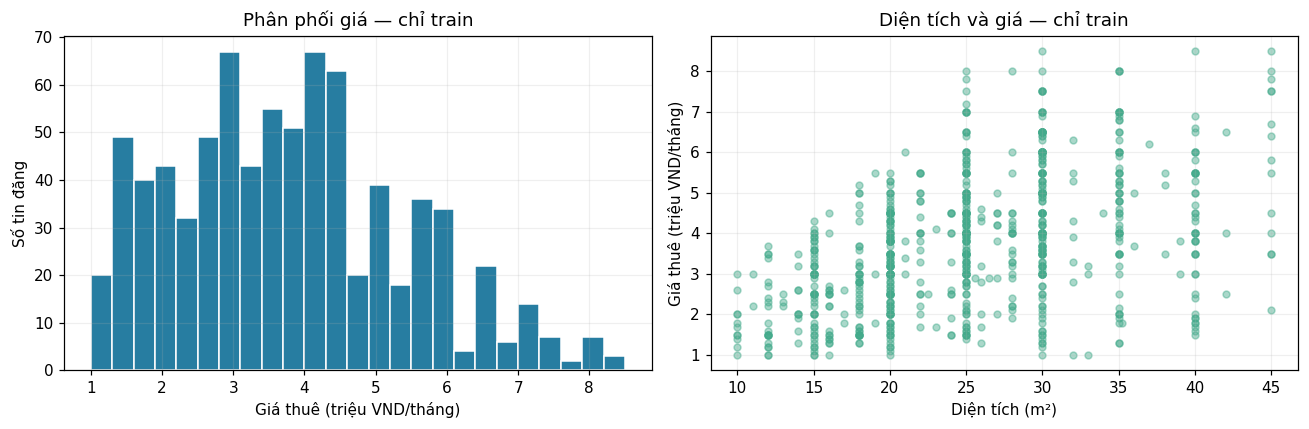

In [4]:
display(X_train.isna().agg(['sum', 'mean']).T.rename(
    columns={'sum': 'Số giá trị thiếu', 'mean': 'Tỷ lệ thiếu'}
))
display(y_train.describe(percentiles=[.1, .25, .5, .75, .9, .95]).to_frame('Giá thuê train (VND)'))
print('Số nhóm phân loại trên train:', X_train[CATEGORICAL_FEATURES].nunique().to_dict())
if X_train['district'].isna().mean() > 0.5:
    warnings.warn('Hơn một nửa giá trị district bị thiếu/không xác định; cần xem lại bước trích xuất địa điểm.')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train / 1e6, bins=25, edgecolor='white', color='#277DA1')
axes[0].set(xlabel='Giá thuê (triệu VND/tháng)', ylabel='Số tin đăng', title='Phân phối giá — chỉ train')
axes[1].scatter(X_train['area_m2'], y_train / 1e6, s=20, alpha=.45, color='#43AA8B')
axes[1].set(xlabel='Diện tích (m²)', ylabel='Giá thuê (triệu VND/tháng)', title='Diện tích và giá — chỉ train')
fig.tight_layout()
plt.show()


## 7. Tiền xử lý trong pipeline và không gian tìm kiếm

Điền thiếu bằng trung vị của phần train trong từng fold; biến phân loại thiếu được giữ thành nhóm `__MISSING__`. One-hot bỏ qua nhóm mới khi dự đoán. Pipeline được fit lại trong mỗi fold, tránh học trung vị hoặc danh mục từ test/validation.

Không chuẩn hóa z-score vì hai mô hình dùng cây quyết định. Ma trận one-hot dạng dày phù hợp với dữ liệu ít biến phân loại; nếu mở rộng sang địa chỉ chi tiết có rất nhiều nhóm, cần đánh giá lại bộ nhớ.

Độ sâu cây AdaBoost được khai báo và tinh chỉnh rõ ràng. Mỗi mô hình thử cùng **24 cấu hình lấy mẫu không hoàn lại** từ một không gian hữu hạn 432 cấu hình; điều này kiểm soát ngân sách tìm kiếm, không làm cho thời gian tính toán nhất thiết bằng nhau. Hàm mất mát huấn luyện có thể khác nhau, nhưng tiêu chí chọn cấu hình luôn là MAE.


In [5]:
def make_preprocessor():
    return ColumnTransformer([
        ('numeric', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True),
         NUMERIC_FEATURES),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='constant', fill_value='__MISSING__', keep_empty_features=True)),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
        ]), CATEGORICAL_FEATURES),
    ], sparse_threshold=0)

model_specs = {
    'AdaBoost': {
        'estimator': AdaBoostRegressor(
            estimator=DecisionTreeRegressor(random_state=RANDOM_STATE), random_state=RANDOM_STATE
        ),
        'space': {
            'model__n_estimators': [50, 100, 200, 300],
            'model__learning_rate': [0.03, 0.1, 0.3, 1.0],
            'model__loss': ['linear', 'square', 'exponential'],
            'model__estimator__max_depth': [1, 2, 3],
            'model__estimator__min_samples_leaf': [2, 5, 10],
        },
    },
    'Gradient Boosting': {
        'estimator': GradientBoostingRegressor(random_state=RANDOM_STATE),
        'space': {
            'model__n_estimators': [50, 100, 200, 300],
            'model__learning_rate': [0.03, 0.05, 0.1, 0.2],
            'model__loss': ['squared_error', 'absolute_error', 'huber'],
            'model__max_depth': [1, 2, 3],
            'model__min_samples_leaf': [2, 5, 10],
        },
    },
}


## 8. Tinh chỉnh trên train và chọn mô hình trước đánh giá test

`RandomizedSearchCV` nhận đúng cùng danh sách fold đã tạo. Sai số CV của cấu hình tốt nhất là kết quả đã qua chọn lựa nên có thể lạc quan; không gọi đó là ước lượng độc lập cuối cùng. Độ lệch chuẩn giữa các fold mô tả độ phân tán, **không phải** khoảng tin cậy 95% vì các fold có tập train chồng lấn.


In [6]:
searches, fitted_models, cv_summary = {}, {}, []
for name, spec in model_specs.items():
    pipeline = Pipeline([('preprocess', make_preprocessor()), ('model', clone(spec['estimator']))])
    search = RandomizedSearchCV(
        pipeline, param_distributions=spec['space'], n_iter=SEARCH_ITERATIONS,
        scoring={'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
        refit='mae', cv=cv_folds, random_state=RANDOM_STATE,
        n_jobs=N_JOBS, pre_dispatch=N_JOBS, return_train_score=True, error_score='raise',
    )
    started = perf_counter()
    search.fit(X_train, y_train)
    elapsed = perf_counter() - started
    idx = search.best_index_
    searches[name] = search
    fitted_models[name] = search.best_estimator_
    cv_summary.append({
        'Mô hình': name,
        'CV MAE (VND)': -search.cv_results_['mean_test_mae'][idx],
        'CV MAE SD (VND)': search.cv_results_['std_test_mae'][idx],
        'CV train MAE (VND)': -search.cv_results_['mean_train_mae'][idx],
        'Số cấu hình đã thử': len(search.cv_results_['params']),
        'Tìm kiếm + refit (giây)': elapsed,
    })
    print(f'Hoàn tất {name}: {elapsed:.1f} giây.')

cv_table = pd.DataFrame(cv_summary).set_index('Mô hình').sort_values('CV MAE (VND)')
selected_name = cv_table.index[0]  # Không dùng y_test để lựa chọn.
display(cv_table.round(2))
print('Mô hình được chọn theo CV MAE:', selected_name)

parameter_rows = []
for name, search in searches.items():
    for parameter, value in search.best_params_.items():
        parameter_rows.append({'Mô hình': name, 'Tham số': parameter.removeprefix('model__'), 'Giá trị': str(value)})
best_parameters = pd.DataFrame(parameter_rows)
display(best_parameters)


Hoàn tất AdaBoost: 30.8 giây.
Hoàn tất Gradient Boosting: 43.5 giây.


,CV MAE (VND),CV MAE SD (VND),CV train MAE (VND),Số cấu hình đã thử,Tìm kiếm + refit (giây)
Mô hình,,,,,
Gradient Boosting,836879.02,42190.73,753099.54,24,43.52
AdaBoost,937658.01,38591.65,887840.27,24,30.82


Mô hình được chọn theo CV MAE: Gradient Boosting


,Mô hình,Tham số,Giá trị
0,AdaBoost,n_estimators,50
1,AdaBoost,loss,exponential
2,AdaBoost,learning_rate,0.03
3,AdaBoost,estimator__min_samples_leaf,10
4,AdaBoost,estimator__max_depth,3
5,Gradient Boosting,n_estimators,300
6,Gradient Boosting,min_samples_leaf,2
7,Gradient Boosting,max_depth,2
8,Gradient Boosting,loss,huber
9,Gradient Boosting,learning_rate,0.05


## 9. Đánh giá cuối cùng trên tập kiểm tra giữ riêng

Baseline được kiểm định trên cùng các fold và fit trung vị trên toàn train để dự đoán test. Cột cải thiện là `(MAE_baseline − MAE_model) / MAE_baseline × 100%`; giá trị âm nghĩa là kém hơn baseline. Bảng giữ thứ tự lựa chọn từ CV để tránh vô tình chọn lại mô hình theo test.


In [7]:
BASELINE_NAME = 'Baseline trung vị'
baseline = Pipeline([('preprocess', make_preprocessor()), ('model', DummyRegressor(strategy='median'))])
baseline_cv_mae = -cross_val_score(
    baseline, X_train, y_train, cv=cv_folds, scoring='neg_mean_absolute_error',
    n_jobs=N_JOBS, error_score='raise',
)
baseline.fit(X_train, y_train)
all_models = {BASELINE_NAME: baseline, **fitted_models}
test_predictions = {name: model.predict(X_test) for name, model in all_models.items()}
baseline_mae = mean_absolute_error(y_test, test_predictions[BASELINE_NAME])

def regression_metrics(actual, prediction):
    absolute_error = np.abs(np.asarray(actual) - np.asarray(prediction))
    return {
        'Test MAE (VND)': mean_absolute_error(actual, prediction),
        'Test RMSE (VND)': np.sqrt(mean_squared_error(actual, prediction)),
        'Test R²': r2_score(actual, prediction),
        'Test P90 |sai số| (VND)': np.quantile(absolute_error, .9),
    }

rows = []
for name, model in all_models.items():
    metrics = regression_metrics(y_test, test_predictions[name])
    metrics['Mô hình'] = name
    metrics['Train MAE (VND)'] = mean_absolute_error(y_train, model.predict(X_train))
    metrics['CV MAE (VND)'] = baseline_cv_mae.mean() if name == BASELINE_NAME else cv_table.loc[name, 'CV MAE (VND)']
    metrics['CV MAE SD (VND)'] = baseline_cv_mae.std() if name == BASELINE_NAME else cv_table.loc[name, 'CV MAE SD (VND)']
    metrics['Giảm MAE so baseline (%)'] = (100 * (baseline_mae - metrics['Test MAE (VND)']) / baseline_mae
                                                  if baseline_mae > 0 else np.nan)
    rows.append(metrics)
comparison = pd.DataFrame(rows).set_index('Mô hình').loc[[BASELINE_NAME] + cv_table.index.tolist()]
display(comparison.round(3))
print('Các giá trị sai số đều là VND/tháng; R² và phần trăm cải thiện không có đơn vị tiền tệ.')


,Test MAE (VND),Test RMSE (VND),Test R²,Test P90 |sai số| (VND),Train MAE (VND),CV MAE (VND),CV MAE SD (VND),Giảm MAE so baseline (%)
Mô hình,,,,,,,,
Baseline trung vị,1420303.030,1729992.410,-0.002,2600000.000,1302705.436,1306389.539,56028.669,0.000
Gradient Boosting,834967.185,1109008.087,0.588,1786170.679,762488.740,836879.019,42190.733,41.212
AdaBoost,924363.042,1178401.654,0.535,1902975.773,882734.381,937658.009,38591.654,34.918


Các giá trị sai số đều là VND/tháng; R² và phần trăm cải thiện không có đơn vị tiền tệ.


## 10. Chênh lệch MAE và mức bất định trên test

Đặt **Δ = MAE(AdaBoost) − MAE(Gradient Boosting)**. Δ > 0 nghiêng về Gradient Boosting, Δ < 0 nghiêng về AdaBoost.

Bootstrap **ghép cặp**: cùng một mẫu test được dùng cho cả hai bộ dự đoán. Nếu cùng URL có nhiều bản ghi, lấy mẫu lại cả nhóm URL, tránh giả định các bản ghi cùng tin là độc lập. Khoảng percentile 95% là mô tả bất định lấy mẫu test **với mô hình đã fit cố định**; không bao gồm toàn bộ bất định do huấn luyện, chọn tham số hoặc thay đổi thị trường. Đây không phải khoảng dự đoán giá cho một phòng.


In [8]:
paired_errors = pd.DataFrame({
    'group': groups_test.to_numpy(),
    'difference': np.abs(y_test.to_numpy() - test_predictions['AdaBoost'])
                  - np.abs(y_test.to_numpy() - test_predictions['Gradient Boosting']),
})
group_errors = paired_errors.groupby('group', sort=False)['difference'].agg(['sum', 'count'])
if len(group_errors) < 2:
    raise ValueError('Cần ít nhất hai nhóm test để bootstrap.')
if len(group_errors) < 30:
    warnings.warn('Ít hơn 30 nhóm test; khoảng bootstrap có thể không ổn định.')
sums, counts = group_errors['sum'].to_numpy(), group_errors['count'].to_numpy()
rng = np.random.default_rng(RANDOM_STATE)
bootstrap_deltas = np.empty(BOOTSTRAP_REPEATS)
for i in range(BOOTSTRAP_REPEATS):
    sampled = rng.integers(0, len(group_errors), size=len(group_errors))
    bootstrap_deltas[i] = sums[sampled].sum() / counts[sampled].sum()
delta_mae = paired_errors['difference'].mean()
ci_low, ci_high = np.quantile(bootstrap_deltas, [.025, .975])
print(f'Δ MAE (AdaBoost − Gradient Boosting): {delta_mae:,.0f} VND/tháng')
print(f'Khoảng bootstrap ghép cặp 95%: [{ci_low:,.0f}; {ci_high:,.0f}] VND/tháng')
if ci_low > 0:
    uncertainty_note = 'Khoảng bootstrap nằm trên 0, nghiêng về Gradient Boosting trong mẫu test hiện tại.'
elif ci_high < 0:
    uncertainty_note = 'Khoảng bootstrap nằm dưới 0, nghiêng về AdaBoost trong mẫu test hiện tại.'
else:
    uncertainty_note = 'Khoảng bootstrap chứa 0; chưa có bằng chứng rõ về ưu thế MAE trên mẫu test này.'
print(uncertainty_note)


Δ MAE (AdaBoost − Gradient Boosting): 89,396 VND/tháng
Khoảng bootstrap ghép cặp 95%: [25,355; 151,543] VND/tháng
Khoảng bootstrap nằm trên 0, nghiêng về Gradient Boosting trong mẫu test hiện tại.


## 11. Chẩn đoán sai số và giải thích mô hình

Hai biểu đồ thực tế–dự đoán có cùng thang đo. Điểm dưới đường chéo là dự đoán thấp; phần dư = thực tế − dự đoán nên phần dư dương cũng là dự đoán thấp. Phân tích theo nhóm giá dùng ngưỡng lấy từ train, không chọn ngưỡng để làm đẹp test. Nhóm ít quan sát chỉ mang tính tham khảo.


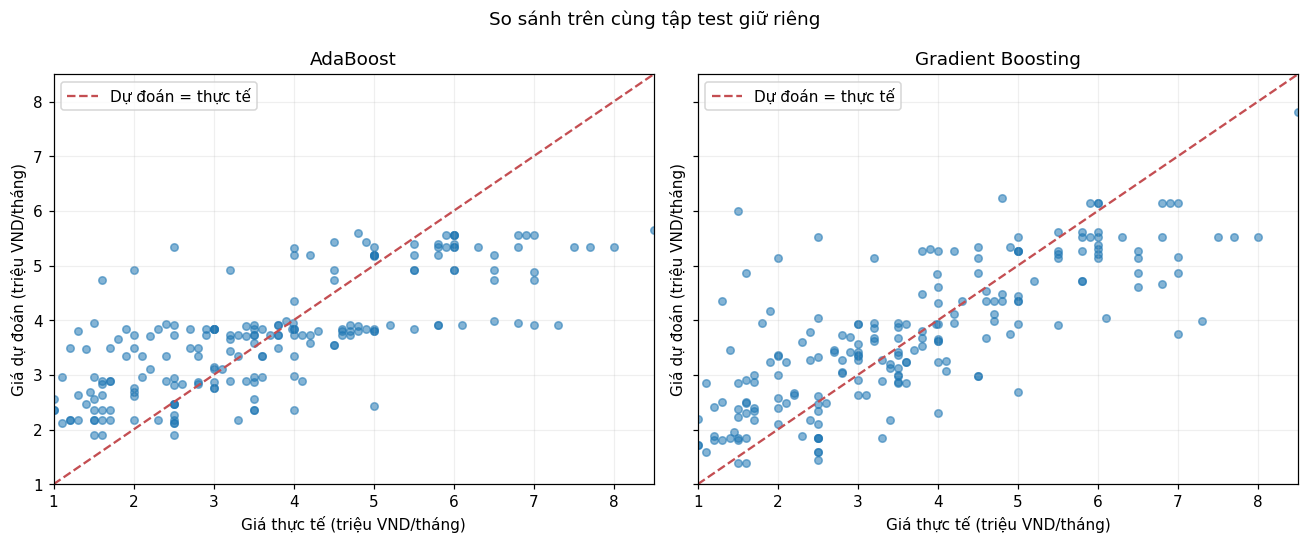

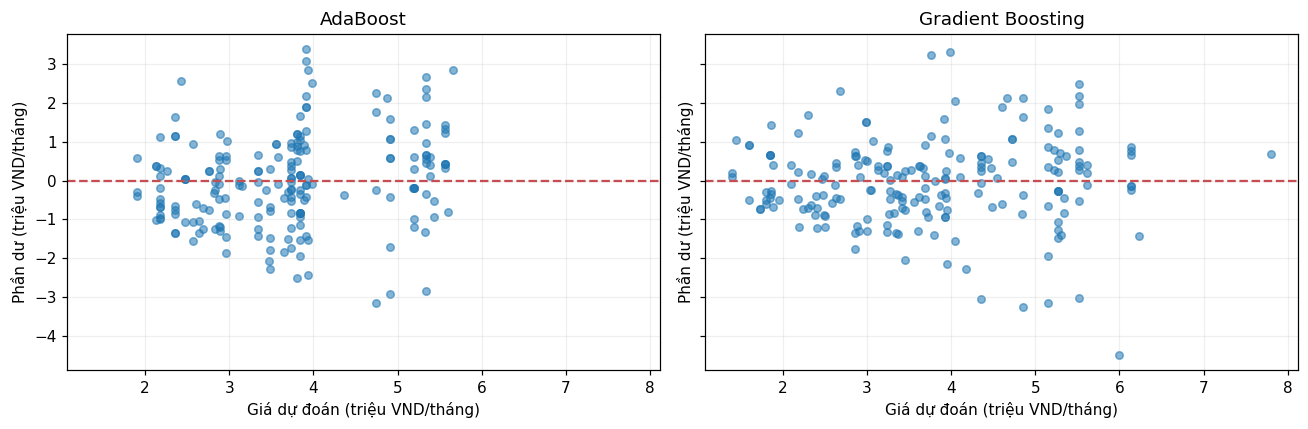

,Mô hình,Nhóm giá theo ngưỡng train,n,MAE_VND,mean_residual_VND
0,AdaBoost,"(-inf, 3000000.0]",83,989476.0,-923694.0
1,AdaBoost,"(3000000.0, 4300000.0]",50,503375.0,106275.0
2,AdaBoost,"(4300000.0, inf]",65,1165056.0,1041793.0
3,Gradient Boosting,"(-inf, 3000000.0]",83,908510.0,-740740.0
4,Gradient Boosting,"(3000000.0, 4300000.0]",50,565260.0,34179.0
5,Gradient Boosting,"(4300000.0, inf]",65,948526.0,774815.0


In [9]:
model_names = list(model_specs)
values = np.concatenate([y_test.to_numpy()] + [test_predictions[n] for n in model_names]) / 1e6
low, high = values.min(), values.max()
fig_prediction, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, name in zip(axes, model_names):
    ax.scatter(y_test / 1e6, test_predictions[name] / 1e6, alpha=.55, s=24)
    ax.plot([low, high], [low, high], '--', color='#C44E52', label='Dự đoán = thực tế')
    ax.set(xlim=(low, high), ylim=(low, high), title=name,
           xlabel='Giá thực tế (triệu VND/tháng)', ylabel='Giá dự đoán (triệu VND/tháng)')
    ax.legend()
fig_prediction.suptitle('So sánh trên cùng tập test giữ riêng')
fig_prediction.tight_layout()
plt.show()

fig_residuals, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for ax, name in zip(axes, model_names):
    ax.scatter(test_predictions[name] / 1e6, (y_test - test_predictions[name]) / 1e6, alpha=.55, s=24)
    ax.axhline(0, color='#C44E52', linestyle='--')
    ax.set(title=name, xlabel='Giá dự đoán (triệu VND/tháng)', ylabel='Phần dư (triệu VND/tháng)')
fig_residuals.tight_layout()
plt.show()

q_low, q_high = y_train.quantile([1/3, 2/3])
test_price_band = pd.cut(y_test, bins=np.unique([-np.inf, q_low, q_high, np.inf]), include_lowest=True)
band_rows = []
for name in model_names:
    diagnostic = pd.DataFrame({
        'Nhóm giá theo ngưỡng train': test_price_band,
        'Sai số tuyệt đối (VND)': np.abs(y_test - test_predictions[name]),
        'Phần dư (VND)': y_test - test_predictions[name],
    })
    table = diagnostic.groupby('Nhóm giá theo ngưỡng train', observed=True).agg(
        n=('Sai số tuyệt đối (VND)', 'size'),
        MAE_VND=('Sai số tuyệt đối (VND)', 'mean'),
        mean_residual_VND=('Phần dư (VND)', 'mean'),
    ).reset_index()
    table.insert(0, 'Mô hình', name)
    band_rows.append(table)
band_diagnostics = pd.concat(band_rows, ignore_index=True)
display(band_diagnostics.round(0))


**Tầm quan trọng hoán vị trên các biến gốc:** đo mức MAE tăng khi xáo trộn từng cột test của mô hình đã chọn từ CV. Đây là chẩn đoán sau lựa chọn, không dùng để tinh chỉnh tiếp. Biến tương quan có thể chia sẻ tầm quan trọng; giá trị âm có thể do nhiễu. Không diễn giải thành tác động nhân quả hay mức tăng giá thuê do thay đổi một đặc điểm.


In [10]:
importance = permutation_importance(
    fitted_models[selected_name], X_test, y_test,
    scoring='neg_mean_absolute_error', n_repeats=10, random_state=RANDOM_STATE, n_jobs=N_JOBS,
)
importance_table = pd.DataFrame({
    'Biến': FEATURES,
    'MAE tăng trung bình (VND)': importance.importances_mean,
    'SD giữa lần hoán vị (VND)': importance.importances_std,
}).sort_values('MAE tăng trung bình (VND)', ascending=False)
display(importance_table.round(0))


,Biến,MAE tăng trung bình (VND),SD giữa lần hoán vị (VND)
1,district,370908.0,41106.0
0,area_m2,326253.0,34037.0
2,furniture_status,132903.0,15439.0


## 12. Kết luận tự động từ kết quả đã chạy
**Kết quả thực nghiệm**
* Chọn theo CV MAE: Gradient Boosting, MAE CV = 836,879 VND/tháng.
* Trên test giữ riêng: MAE = 834,967 VND/tháng; RMSE = 1,109,008 VND/tháng; R² = 0.588.
* So với trung vị train: giảm MAE 585,336 VND/tháng (41.2%). Mô hình được chọn cải thiện so với baseline.
* Đối chiếu thứ hạng: Nhất quán: mô hình được chọn theo CV cũng có MAE test thấp nhất trong hai mô hình.
* Độ chắc chắn của chênh lệch hai mô hình: Δ MAE = 89,396 VND/tháng; khoảng bootstrap 95% [25,355; 151,543]. Khoảng bootstrap nằm trên 0, nghiêng về Gradient Boosting trong mẫu test hiện tại.

**Khuyến nghị và giới hạn**

Ưu thế quan sát được của Gradient Boosting phù hợp với khả năng mô hình hóa quan hệ phi tuyến và tương tác giữa các đặc trưng của bài toán giá thuê. Tuy nhiên, kết luận chỉ áp dụng cho dữ liệu, tập đặc trưng và thiết kế thực nghiệm hiện tại; cần kiểm chứng lại bằng đánh giá cùng ngân sách tinh chỉnh và phân tích độ bất định của chênh lệch sai số khi thay đổi dữ liệu.